In [1]:
import numpy as np
from scipy.linalg import eigh
import matplotlib.pyplot as plt

from scipy.constants import e, hbar, h

The physical system's Hamiltonian operator looks like this:

$$
\hat H_0 =
4E_C(\hat n-n_g)^2-E_J\cos\hat\varphi
$$

Now to express it in the charge basis:

$$
-E_J\cos\hat\varphi
=
-\frac{E_J}{2}
\left(e^{i\hat\varphi}+e^{-i\hat\varphi}\right).
$$

$$
e^{i\hat\varphi}|N\rangle=|N+1\rangle,
$$

$$
e^{-i\hat\varphi}|N\rangle=|N-1\rangle
$$

So the Hamiltonian becomes

$$
H=
\sum_N 4E_C(N-n_g)^2|N\rangle\langle N|
-\frac{E_J}{2}
\sum_N
\left(
|N+1\rangle\langle N|
+
|N\rangle\langle N+1|
\right)
$$

After choosing the cutoff value for the charge states, the Hamiltonian is a finite matrix:

$$
H_{nn}=4E_C(n-n_g)^2
$$

$$
H_{n,n+1}=H_{n+1,n}=-\frac{E_J}{2}.
$$

In [2]:
# The hamiltonian function

def transmon_hamiltonian(EJ, EC, ng=0, N=20):

    n = np.arange(-N, N+1)

    H = np.diag(4 * EC * (n-ng)**2)

    for i in range(len(n)-1):
        H[i, i+1] = -EJ/2
        H[i+1, i] = -EJ/2

    return H

### Transmon energy spectrum approximation (Duffing oscillator approximation)

$$
E_m\approx
-E_J+
\sqrt{8E_JE_C}\left(m+\frac12\right)
-\frac{E_C}{12}(6m^2+6m+3)
$$

Level 0 error with N=5: -7.70161377539003e-05
Level 1 error with N=5: -0.0010490269601083992


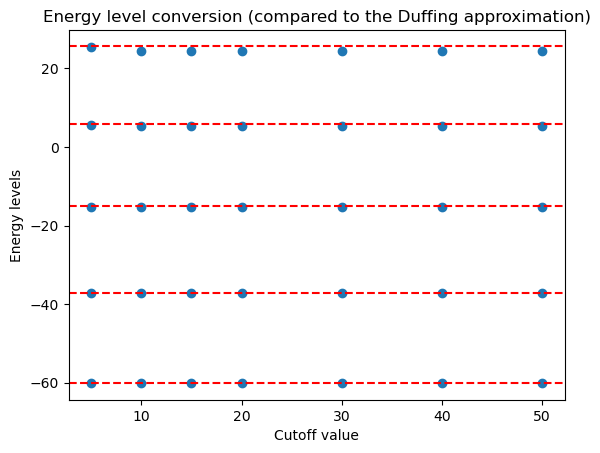

In [7]:
# Checking energy levels convergence for different cutoff values

cutoff = [5, 10, 15, 20, 30, 40, 50]
x = []
y = []

EJ = 71.8
EC = 1.0

for N in cutoff:

    H = transmon_hamiltonian(EJ, EC, N=N)
    energies, states = eigh(H)
    for energy in energies[:5]:
        x.append(N)
        y.append(energy)

    if N == 5:
        energy0_N5 = energies[0]
        energy1_N5 = energies[1]

plt.scatter(x, y)

# Calculating and plotting the theoretical approximation as reference
for level in [0, 1, 2, 3, 4]:
    energy = -EJ + np.sqrt(8*EJ*EC)*(level+0.5) - (EC/12)*(6*(level**2) + 6*level + 3)
    plt.axhline(y=energy, color='r', linestyle='--', linewidth=1.5)

    if level == 0:
        print(f"Level 0 error with N=5: {abs(energy0_N5-energy)/energy}")
    if level == 1:
        print(f"Level 1 error with N=5: {abs(energy1_N5-energy)/energy}")

plt.xlabel("Cutoff value")
plt.ylabel("Energy levels")
plt.title("Energy level conversion (compared to the Duffing approximation)")

plt.show()
    

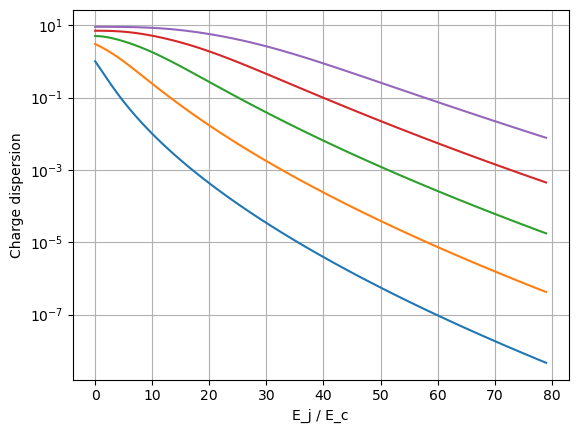

In [4]:
# Calculation and plotting of charge dispersion in relation to EJ/EC

EJ_list = np.arange(0, 80)
EC = 1.0

ej_over_ec = []
epsilon0 = []
epsilon1 = []
epsilon2 = []
epsilon3 = []
epsilon4 = []

for EJ_value in EJ_list:
    H = transmon_hamiltonian(EJ_value, EC, ng=0.0)
    H_05 = transmon_hamiltonian(EJ_value, EC, ng=0.5)
    energies, states = eigh(H)
    energies_05, states_05 = eigh(H_05)

    epsilon0.append(abs(energies[0] - energies_05[0]))
    epsilon1.append(abs(energies[1] - energies_05[1]))
    epsilon2.append(abs(energies[2] - energies_05[2]))
    epsilon3.append(abs(energies[3] - energies_05[3]))
    epsilon4.append(abs(energies[4] - energies_05[4]))
    
    ej_over_ec.append(EJ_value/EC)

plt.plot(ej_over_ec, epsilon0)
plt.plot(ej_over_ec, epsilon1)
plt.plot(ej_over_ec, epsilon2)
plt.plot(ej_over_ec, epsilon3)
plt.plot(ej_over_ec, epsilon4)

plt.xlabel("E_j / E_c")
plt.ylabel("Charge dispersion")
plt.yscale("log")
plt.grid()
plt.show()


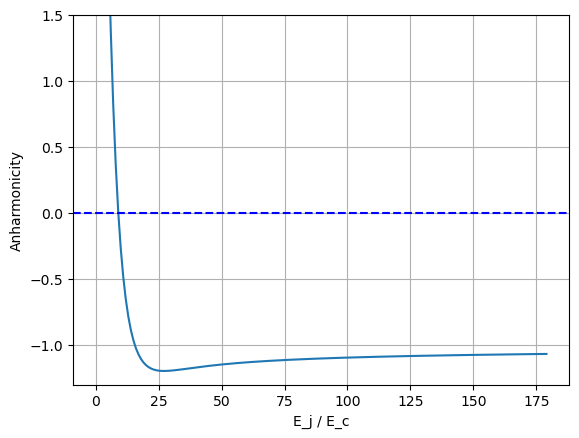

In [5]:
# Calculating and plotting the anharmonicity in relation to EJ/EC

EJ_list = np.arange(0, 180)
EC = 1.0

anharmonicities = []
ej_over_ec = []

for EJ_value in EJ_list:
    H = transmon_hamiltonian(EJ_value, EC, ng=0.5)
    energies, states = eigh(H)

    anharm = energies[2] - 2*energies[1] + energies[0]
    anharmonicities.append(anharm)

    ej_over_ec.append(EJ_value/EC)

plt.plot(ej_over_ec, anharmonicities)
plt.axhline(y=0, color='b', linestyle='--', linewidth=1.5)

plt.xlabel("E_j / E_c")
plt.ylabel("Anharmonicity")
plt.grid()
plt.ylim(-1.3, 1.5)
plt.show()


In [6]:
# Defining the physical parameters and finding the energies and states for
# the resulting system. Then calculating the transition frequency between ground state and first excited state,
# and the anharmonicity - difference between the 0-1 transition frequency and 1-2 transition frequency

C = 70e-15       # 70 fF
Ic = 40e-9       # 40 nA

EC = e**2 / (2*C)
EJ = hbar*Ic / (2*e)

print("EC/h =", f"{EC/h:.4e}", "Hz")
print("EJ/h =", f"{EJ/h:.4e}", "Hz")
print("EJ/EC =", EJ/EC)

H = transmon_hamiltonian(EJ, EC)

energies, states = eigh(H)

transition_freq = (energies[1] - energies[0])/h
anharmonicity = (energies[2] - energies[1])/h - transition_freq

print("Transition frequency 01 =", f"{transition_freq:.4e}", "Hz")
print("Anharmonicity =", f"{anharmonicity:.4e}", "Hz")


EC/h = 2.7672e+08 Hz
EJ/h = 1.9867e+10 Hz
EJ/EC = 71.79645665858247
Transition frequency 01 = 6.3421e+09 Hz
Anharmonicity = -3.0917e+08 Hz


In [ ]:
# Optional: validation against scqubits

import scqubits as scq

ec_hz = 2.7672e8
ej_hz = 1.9867e10

# Create a Transmon instance (set ncut large enough for convergence)
tmon = scq.Transmon(EJ=ej_hz, EC=ec_hz, ng=0.0, ncut=35)

# 0-1 splitting (in Hz when EJ and EC are passed in Hz)
f_01_hz = tmon.E01()
print(f"scqubits f_01 = {f_01_hz:.6e} Hz ({f_01_hz / 1e9:.6f} GHz)")
print(f"Error: {abs(transition_freq-f_01_hz)/f_01_hz}")

0.00005

scqubits f_01 = 6.342033e+09 Hz (6.342033 GHz)
Error: 4.785189191804947e-06
